In [ ]:
!pip -q install ucimlrepo statsmodels seaborn

import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error
)
from IPython.display import display

warnings.filterwarnings("ignore")

ROLL_NUMBER = 2139
RANDOM_STATE = ROLL_NUMBER % 1000  # 139

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

OUTPUT_DIR = "assignment_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Roll number:", ROLL_NUMBER)
print("Random state:", RANDOM_STATE)
print("Output directory:", OUTPUT_DIR)

Roll number: 2139
Random state: 139
Output directory: assignment_results


In [ ]:
# Download the Adult Census Income dataset from UCI
adult = fetch_ucirepo(id=2)

X_raw = adult.data.features.copy()
y_raw = adult.data.targets.copy()

print("Feature shape:", X_raw.shape)
print("Target shape:", y_raw.shape)

display(X_raw.head())
display(y_raw.head())

print("\nFeature columns:")
print(X_raw.columns.tolist())

print("\nTarget columns:")
print(y_raw.columns.tolist())

Feature shape: (48842, 14)
Target shape: (48842, 1)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba


,income
0,<=50K
1,<=50K
2,<=50K
3,<=50K
4,<=50K



Feature columns:
['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country']

Target columns:
['income']


In [ ]:
# Standardize column names
X_raw.columns = X_raw.columns.str.strip().str.lower()

# Normalize categorical values and represent '?' as missing
for col in X_raw.select_dtypes(include=["object", "category"]).columns:
    X_raw[col] = X_raw[col].astype("string").str.strip()
    X_raw[col] = X_raw[col].replace(
        {"?": pd.NA, "": pd.NA, "nan": pd.NA}
    )

# Normalize the target labels
target = y_raw.iloc[:, 0].astype("string").str.strip()
target = target.str.replace(".", "", regex=False)

valid_target = target.isin([">50K", "<=50K"])

X_raw = X_raw.loc[valid_target].reset_index(drop=True)
target = target.loc[valid_target].reset_index(drop=True)

y = (target == ">50K").astype(int)

# Remove duplicates before splitting
data = X_raw.copy()
data["income"] = y
data = data.drop_duplicates().reset_index(drop=True)

y = data.pop("income").astype(int)
X = data.copy()

print("Clean dataset shape:", X.shape)
print("\nIncome distribution:")
display(y.value_counts().rename(index={0: "<=50K", 1: ">50K"}).to_frame("count"))

print("\nMissing values before imputation:")
display(
    X.isna().sum()
      .sort_values(ascending=False)
      .to_frame("missing_count")
      .query("missing_count > 0")
)

print("\nSensitive variables:")
print("sex:", X["sex"].value_counts(dropna=False).to_dict())
print("race:", X["race"].value_counts(dropna=False).to_dict())

Clean dataset shape: (48790, 14)

Income distribution:


,count
income,
<=50K,37109
>50K,11681



Missing values before imputation:


,missing_count
occupation,2805
workclass,2795
native-country,856



Sensitive variables:
sex: {'Male': 32614, 'Female': 16176}
race: {'White': 41714, 'Black': 4683, 'Asian-Pac-Islander': 1517, 'Amer-Indian-Eskimo': 470, 'Other': 406}


In [ ]:

# CELL 4 — Train-test split and corrected preprocessing

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
import pandas as pd
import numpy as np

# Convert nullable Pandas strings to ordinary Python objects.
# Replace pd.NA with np.nan so scikit-learn can detect missing values.
X = X.copy()

for col in X.columns:
    if (
        pd.api.types.is_string_dtype(X[col])
        or X[col].dtype == object
        or isinstance(X[col].dtype, pd.CategoricalDtype)
    ):
        X[col] = X[col].astype(object)
        X[col] = X[col].where(pd.notna(X[col]), np.nan)

# Ensure numeric columns have proper numeric dtypes.
for col in X.columns:
    if col in ["age", "fnlwgt", "education-num", "capital-gain",
               "capital-loss", "hours-per-week"]:
        X[col] = pd.to_numeric(X[col], errors="coerce")

# Rebuild the split using your assigned seed.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=139,
    stratify=y
)

numeric_cols = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = [
    col for col in X_train.columns if col not in numeric_cols
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        drop="first",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

# Fit only on training data to prevent leakage.
X_train_array = preprocessor.fit_transform(X_train)
X_test_array = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_array,
    columns=feature_names,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_array,
    columns=feature_names,
    index=X_test.index
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Numeric features:", len(numeric_cols))
print("Categorical features:", len(categorical_cols))
print("Encoded feature count:", len(feature_names))
print("Missing values handled successfully.")
print("Training matrix shape:", X_train_processed.shape)
print("Testing matrix shape:", X_test_processed.shape)


Training samples: 34153
Testing samples: 14637
Numeric features: 6
Categorical features: 8
Encoded feature count: 96
Missing values handled successfully.
Training matrix shape: (34153, 96)
Testing matrix shape: (14637, 96)


In [ ]:
# Model A: Linear Regression (OLS-style least squares)
model_a = LinearRegression()
model_a.fit(X_train_processed, y_train)

linear_predictions = model_a.predict(X_test_processed)

# OLS predictions are not constrained to [0, 1].
# This is a limitation worth discussing in the report.

# Model B: Logistic Regression
model_b = LogisticRegression(
    max_iter=2000,
    random_state=RANDOM_STATE
)
model_b.fit(X_train_processed, y_train)

logistic_probabilities = model_b.predict_proba(X_test_processed)[:, 1]
logistic_predictions = (logistic_probabilities >= 0.5).astype(int)

# Metrics
metrics = pd.DataFrame([
    {
        "model": "Linear Regression",
        "accuracy_at_0.5": accuracy_score(
            y_test, (linear_predictions >= 0.5).astype(int)
        ),
        "MAE": mean_absolute_error(y_test, linear_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, linear_predictions)),
        "ROC_AUC": roc_auc_score(y_test, linear_predictions)
    },
    {
        "model": "Logistic Regression",
        "accuracy_at_0.5": accuracy_score(y_test, logistic_predictions),
        "MAE": mean_absolute_error(y_test, logistic_probabilities),
        "RMSE": np.sqrt(mean_squared_error(y_test, logistic_probabilities)),
        "ROC_AUC": roc_auc_score(y_test, logistic_probabilities)
    }
])

display(metrics.round(4))
metrics.to_csv(f"{OUTPUT_DIR}/part1_model_metrics.csv", index=False)

print("Linear regression prediction range:",
      round(linear_predictions.min(), 4),
      "to", round(linear_predictions.max(), 4))

print("\nLogistic regression classification report:")
print(classification_report(
    y_test, logistic_predictions,
    target_names=["<=50K", ">50K"],
    zero_division=0
))

,model,accuracy_at_0.5,MAE,RMSE,ROC_AUC
0,Linear Regression,0.8379,0.2651,0.3417,0.8904
1,Logistic Regression,0.8497,0.2068,0.3214,0.9037


Linear regression prediction range: -0.3814 to 1.6816

Logistic regression classification report:
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.90     11133
        >50K       0.73      0.59      0.65      3504

    accuracy                           0.85     14637
   macro avg       0.80      0.76      0.78     14637
weighted avg       0.84      0.85      0.84     14637



Median linear prediction: 0.23105
Logistic probability threshold: 0.5
Mismatched cases: 4545
Mismatch percentage: 31.05 %


,Logistic: Low,Logistic: High
Linear: Low,7298,20
Linear: High,4525,2794


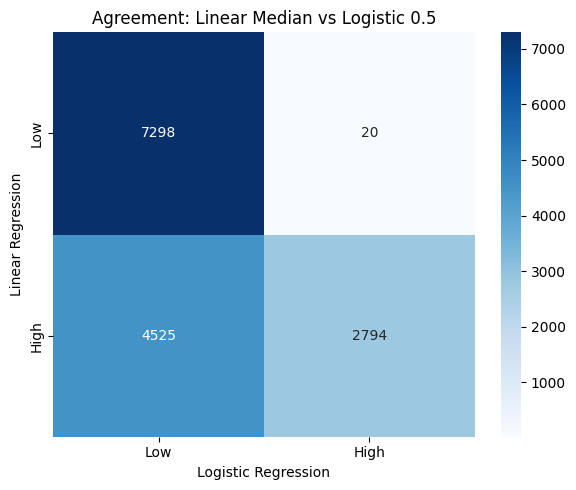

In [ ]:
linear_median = np.median(linear_predictions)

linear_high_risk = (linear_predictions >= linear_median).astype(int)
logistic_high_risk = (logistic_probabilities >= 0.5).astype(int)

# Rows = Model A; columns = Model B
agreement_matrix = confusion_matrix(
    linear_high_risk, logistic_high_risk, labels=[0, 1]
)

mismatch_mask = linear_high_risk != logistic_high_risk
mismatch_count = int(mismatch_mask.sum())
mismatch_percentage = mismatch_count / len(y_test) * 100

print("Median linear prediction:", round(linear_median, 5))
print("Logistic probability threshold: 0.5")
print("Mismatched cases:", mismatch_count)
print("Mismatch percentage:", round(mismatch_percentage, 2), "%")

display(pd.DataFrame(
    agreement_matrix,
    index=["Linear: Low", "Linear: High"],
    columns=["Logistic: Low", "Logistic: High"]
))

comparison_df = pd.DataFrame({
    "actual_income": y_test.to_numpy(),
    "linear_prediction": linear_predictions,
    "logistic_probability": logistic_probabilities,
    "linear_class": linear_high_risk,
    "logistic_class": logistic_high_risk,
    "mismatch": mismatch_mask
}, index=y_test.index)

comparison_df.to_csv(
    f"{OUTPUT_DIR}/part1_threshold_comparison.csv", index=True
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    agreement_matrix, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Low", "High"],
    yticklabels=["Low", "High"]
)
plt.title("Agreement: Linear Median vs Logistic 0.5")
plt.xlabel("Logistic Regression")
plt.ylabel("Linear Regression")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/part1_confusion_matrix.png", dpi=200)
plt.show()

In [ ]:
# Use statsmodels for interpretable coefficients and confidence intervals.
# Age is standardized using the training set's age mean and standard deviation.

age_mean = X_train["age"].mean()
age_std = X_train["age"].std()
if age_std == 0:
    age_std = 1.0

def prepare_age_gender(frame):
    result = pd.DataFrame(index=frame.index)
    result["age_z"] = (frame["age"] - age_mean) / age_std
    result["education_num"] = pd.to_numeric(
        frame["education-num"], errors="coerce"
    )
    result["hours_per_week"] = pd.to_numeric(
        frame["hours-per-week"], errors="coerce"
    )
    result["capital_gain"] = np.log1p(
        pd.to_numeric(frame["capital-gain"], errors="coerce").clip(lower=0)
    )
    result["male"] = (frame["sex"].astype(str) == "Male").astype(int)
    return result

X_sub_train = prepare_age_gender(X_train)
subgroup_data = X_sub_train.copy()
subgroup_data["income"] = y_train

def fit_logit_table(frame, predictors):
    frame = frame[predictors + ["income"]].dropna().copy()
    X_sm = sm.add_constant(frame[predictors], has_constant="add")
    model = sm.Logit(frame["income"], X_sm).fit(disp=False, maxiter=300)
    ci = model.conf_int()
    return pd.DataFrame({
        "coefficient": model.params,
        "std_error": model.bse,
        "p_value": model.pvalues,
        "CI_lower": ci[0],
        "CI_upper": ci[1]
    }), model

predictors = [
    "age_z", "education_num", "hours_per_week", "capital_gain", "male"
]

full_subgroup_table, full_subgroup_model = fit_logit_table(
    subgroup_data, predictors
)

male_data = subgroup_data[subgroup_data["male"] == 1].copy()
female_data = subgroup_data[subgroup_data["male"] == 0].copy()

male_table, male_model = fit_logit_table(
    male_data, ["age_z", "education_num", "hours_per_week", "capital_gain"]
)
female_table, female_model = fit_logit_table(
    female_data, ["age_z", "education_num", "hours_per_week", "capital_gain"]
)

simpson_results = pd.DataFrame({
    "full_dataset": full_subgroup_table.loc[
        ["age_z", "education_num", "hours_per_week", "capital_gain"],
        "coefficient"
    ],
    "male_subgroup": male_table.loc[
        ["age_z", "education_num", "hours_per_week", "capital_gain"],
        "coefficient"
    ],
    "female_subgroup": female_table.loc[
        ["age_z", "education_num", "hours_per_week", "capital_gain"],
        "coefficient"
    ]
})

display(simpson_results.round(4))

# Confidence intervals and p-values for age
age_ci_table = pd.DataFrame({
    "model": ["Full dataset", "Male subgroup", "Female subgroup"],
    "age_coefficient": [
        full_subgroup_table.loc["age_z", "coefficient"],
        male_table.loc["age_z", "coefficient"],
        female_table.loc["age_z", "coefficient"]
    ],
    "CI_lower": [
        full_subgroup_table.loc["age_z", "CI_lower"],
        male_table.loc["age_z", "CI_lower"],
        female_table.loc["age_z", "CI_lower"]
    ],
    "CI_upper": [
        full_subgroup_table.loc["age_z", "CI_upper"],
        male_table.loc["age_z", "CI_upper"],
        female_table.loc["age_z", "CI_upper"]
    ],
    "p_value": [
        full_subgroup_table.loc["age_z", "p_value"],
        male_table.loc["age_z", "p_value"],
        female_table.loc["age_z", "p_value"]
    ]
})

display(age_ci_table.round(5))
simpson_results.to_csv(f"{OUTPUT_DIR}/part2_1_subgroup_coefficients.csv")
age_ci_table.to_csv(f"{OUTPUT_DIR}/part2_1_age_confidence_intervals.csv", index=False)

# Compare the signs of the age coefficients
signs = np.sign(age_ci_table["age_coefficient"].to_numpy())
if signs[1] != signs[2]:
    print("The age coefficient reverses sign between male and female subgroups.")
else:
    print("No age-coefficient sign reversal between male and female subgroups.")
    print("Use coefficients, confidence intervals and p-values to discuss differences.")

,full_dataset,male_subgroup,female_subgroup
age_z,0.5769,0.6297,0.4107
education_num,0.3405,0.3350,0.3734
hours_per_week,0.0336,0.0372,0.0203
capital_gain,0.2015,0.1886,0.2410


,model,age_coefficient,CI_lower,CI_upper,p_value
0,Full dataset,0.57691,0.54509,0.60873,0.0
1,Male subgroup,0.62970,0.59310,0.66630,0.0
2,Female subgroup,0.41071,0.34469,0.47674,0.0


No age-coefficient sign reversal between male and female subgroups.
Use coefficients, confidence intervals and p-values to discuss differences.


In [ ]:
# Build a compact interpretable logistic regression design matrix.
# Continuous predictors are standardized from training-set statistics.
def prepare_ovb(frame):
    out = pd.DataFrame(index=frame.index)

    for col in ["age", "education-num", "hours-per-week", "capital-gain"]:
        values = pd.to_numeric(frame[col], errors="coerce")
        if col == "capital-gain":
            values = np.log1p(values.clip(lower=0))
        mean = pd.to_numeric(
            X_train[col], errors="coerce"
        )
        if col == "capital-gain":
            mean = np.log1p(mean.clip(lower=0))
        mu, sd = mean.mean(), mean.std()
        if not np.isfinite(sd) or sd == 0:
            sd = 1
        out[col.replace("-", "_") + "_z"] = (values - mu) / sd

    out["male"] = (frame["sex"].astype(str) == "Male").astype(int)
    return out

ovb_X_train = prepare_ovb(X_train)
ovb_df = ovb_X_train.copy()
ovb_df["income"] = y_train

full_predictors = [
    "age_z", "education_num_z", "hours_per_week_z",
    "capital_gain_z", "male"
]
reduced_predictors = [
    "age_z", "hours_per_week_z", "capital_gain_z", "male"
]

full_ovb_table, full_ovb_model = fit_logit_table(
    ovb_df, full_predictors
)
reduced_ovb_table, reduced_ovb_model = fit_logit_table(
    ovb_df, reduced_predictors
)

common_predictors = reduced_predictors

ovb_results = pd.DataFrame({
    "full_coefficient": full_ovb_table.loc[
        common_predictors, "coefficient"
    ],
    "reduced_coefficient": reduced_ovb_table.loc[
        common_predictors, "coefficient"
    ]
})

ovb_results["absolute_change"] = (
    ovb_results["reduced_coefficient"] - ovb_results["full_coefficient"]
).abs()

ovb_results["percentage_change"] = np.where(
    ovb_results["full_coefficient"].abs() > 1e-10,
    (
        (ovb_results["reduced_coefficient"] -
         ovb_results["full_coefficient"]) /
        ovb_results["full_coefficient"].abs()
    ) * 100,
    np.nan
)

display(ovb_results.round(4))

largest_shift = ovb_results["absolute_change"].idxmax()
print("Omitted variable: education-num")
print("Largest absolute coefficient shift:", largest_shift)
print("Absolute shift:", round(
    ovb_results.loc[largest_shift, "absolute_change"], 5
))

ovb_results.to_csv(f"{OUTPUT_DIR}/part2_2_omitted_variable_bias.csv")

,full_coefficient,reduced_coefficient,absolute_change,percentage_change
age_z,0.5769,0.5268,0.0501,-8.6867
hours_per_week_z,0.4176,0.4797,0.0621,14.8788
capital_gain_z,0.4921,0.5160,0.0239,4.8562
male,1.1476,1.0383,0.1093,-9.5211


Omitted variable: education-num
Largest absolute coefficient shift: male
Absolute shift: 0.10926


In [ ]:
adversarial = X_test.copy()
adversarial["actual_income"] = y_test
adversarial["predicted_probability"] = logistic_probabilities
adversarial["predicted_class"] = logistic_predictions

adversarial["error_type"] = np.select(
    [
        (adversarial["predicted_probability"] >= 0.75) &
        (adversarial["actual_income"] == 0),

        (adversarial["predicted_probability"] <= 0.25) &
        (adversarial["actual_income"] == 1)
    ],
    ["False positive", "False negative"],
    default="Not selected"
)

wrong_confident = adversarial[
    adversarial["error_type"] != "Not selected"
].copy()

wrong_count = len(wrong_confident)
wrong_percentage = wrong_count / len(X_test) * 100

if wrong_count > 50:
    adversarial_sample = wrong_confident.sample(
        n=50, random_state=RANDOM_STATE
    )
else:
    adversarial_sample = wrong_confident.copy()

print("Test-set size:", len(X_test))
print("High-confidence wrong predictions:", wrong_count)
print("Percentage of full test set:", round(wrong_percentage, 2), "%")
print("Rows in selected adversarial subset:", len(adversarial_sample))

display(adversarial_sample.head(10))

# Compare subset demographics against the entire test set.
def demographic_summary(frame, label):
    rows = []
    for col in ["sex", "race"]:
        counts = frame[col].fillna("Missing").value_counts(normalize=True) * 100
        for category, pct in counts.items():
            rows.append({
                "population": label,
                "variable": col,
                "category": category,
                "percentage": pct
            })
    return rows

demographic_comparison = pd.DataFrame(
    demographic_summary(X_test, "Full test set") +
    demographic_summary(adversarial_sample, "Adversarial subset")
)

display(
    demographic_comparison.pivot_table(
        index=["variable", "category"],
        columns="population",
        values="percentage",
        fill_value=0
    ).round(2)
)

# Common characteristics: compare numeric feature means.
numeric_adversarial_cols = [
    col for col in ["age", "education-num", "hours-per-week",
                    "capital-gain", "capital-loss"]
    if col in X_test.columns
]

characteristics = pd.DataFrame({
    "full_test_mean": X_test[numeric_adversarial_cols].mean(),
    "adversarial_mean": adversarial_sample[numeric_adversarial_cols].mean()
})

display(characteristics.round(3))

print("\nError types in the subset:")
display(adversarial_sample["error_type"].value_counts().to_frame("count"))

adversarial_sample.to_csv(
    f"{OUTPUT_DIR}/part2_3_adversarial_subset.csv", index=True
)
demographic_comparison.to_csv(
    f"{OUTPUT_DIR}/part2_3_demographic_comparison.csv", index=False
)
characteristics.to_csv(
    f"{OUTPUT_DIR}/part2_3_numeric_characteristics.csv"
)

Test-set size: 14637
High-confidence wrong predictions: 690
Percentage of full test set: 4.71 %
Rows in selected adversarial subset: 50


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,actual_income,predicted_probability,predicted_class,error_type
3122,26,Private,31290,HS-grad,9,Married-civ-spouse,Adm-clerical,Wife,White,Female,0,0,40,United-States,1,0.236663,0,False negative
25265,32,Private,180284,10th,6,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,1,0.109187,0,False negative
43650,49,Private,189792,Masters,14,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,60,United-States,0,0.834425,1,False positive
20111,68,Local-gov,233954,Masters,14,Widowed,Prof-specialty,Unmarried,Black,Female,0,0,40,United-States,1,0.187615,0,False negative
19076,76,Private,125784,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,40,United-States,0,0.762705,1,False positive
40986,34,Private,320077,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,0,0,50,United-States,1,0.170066,0,False negative
43070,64,Private,237581,7th-8th,4,Married-civ-spouse,Transport-moving,Husband,White,Male,0,0,48,Mexico,1,0.065024,0,False negative
36220,33,Private,205950,Assoc-voc,11,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,1,0.243851,0,False negative
19,43,Self-emp-not-inc,292175,Masters,14,Divorced,Exec-managerial,Unmarried,White,Female,0,0,45,United-States,1,0.122785,0,False negative
35937,31,Private,101562,Bachelors,13,Never-married,Sales,Not-in-family,White,Female,0,0,50,United-States,1,0.064895,0,False negative


population                   Adversarial subset  Full test set
variable category                                             
race     Amer-Indian-Eskimo                 0.0           0.99
         Asian-Pac-Islander                 2.0           3.14
         Black                             10.0           9.57
         Other                              0.0           0.90
         White                             88.0          85.40
sex      Female                            24.0          33.41
         Male                              76.0          66.59

,full_test_mean,adversarial_mean
age,38.674,44.38
education-num,10.081,10.82
hours-per-week,40.407,44.10
capital-gain,1060.561,391.94
capital-loss,87.058,41.02



Error types in the subset:


,count
error_type,
False negative,39
False positive,11


Fairness metrics across decision thresholds:


,threshold,DP,EO,PP,selection_rate_A,selection_rate_B,TPR_A,TPR_B,FPR_A,FPR_B,PPV_A,PPV_B,accuracy
0,0.05,2.0480,1.0301,1.3942,0.7342,0.3585,0.9879,0.9590,0.6232,0.2844,0.4096,0.2938,0.6228
1,0.15,3.1264,1.1760,1.0427,0.5793,0.1853,0.9417,0.8007,0.4206,0.1093,0.4949,0.4746,0.7535
2,0.25,3.3767,1.2120,0.9949,0.4640,0.1374,0.8622,0.7114,0.2898,0.0666,0.5656,0.5685,0.8074
3,0.35,3.3795,1.2028,0.9866,0.3614,0.1070,0.7526,0.6257,0.1903,0.0430,0.6338,0.6424,0.8352
4,0.45,3.3386,1.1807,0.9803,0.2847,0.0853,0.6508,0.5512,0.1245,0.0278,0.6959,0.7098,0.8468
5,0.50,3.2832,1.1891,1.0039,0.2504,0.0763,0.6023,0.5065,0.0965,0.0232,0.7321,0.7292,0.8497
6,0.55,3.2777,1.2322,1.0421,0.2212,0.0675,0.5507,0.4469,0.0770,0.0207,0.7579,0.7273,0.8468
7,0.65,3.2827,1.2026,1.0155,0.1631,0.0497,0.4412,0.3669,0.0414,0.0106,0.8233,0.8107,0.8412
8,0.75,2.9557,1.1221,1.0524,0.1058,0.0358,0.3134,0.2793,0.0149,0.0057,0.9020,0.8571,0.8258
9,0.85,3.1134,1.1355,1.0109,0.0649,0.0209,0.2009,0.1769,0.0055,0.0016,0.9415,0.9314,0.8048


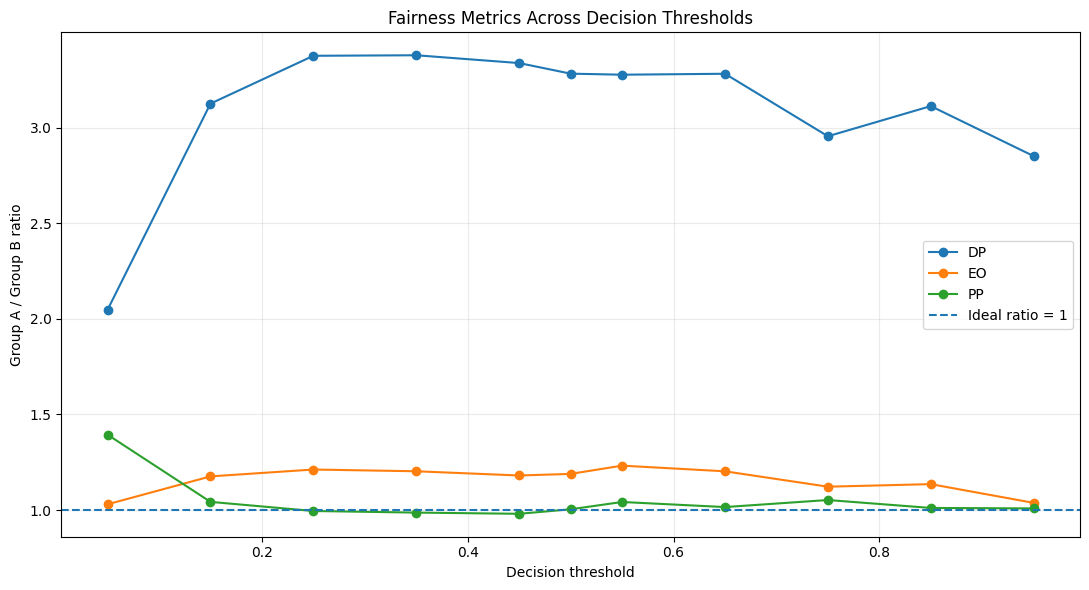

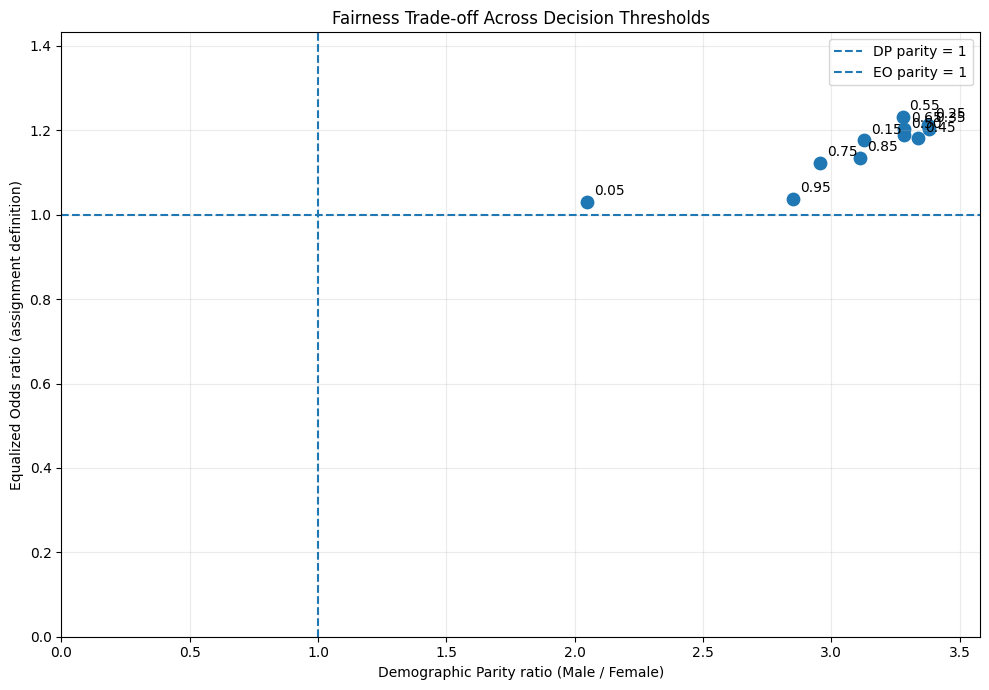

Thresholds ranked by distance to DP = 1 and EO = 1 (exploratory; not necessarily the fairest overall choice):


,threshold,DP,EO,PP,accuracy,distance_to_parity
0,0.05,2.0480,1.0301,1.3942,0.6228,1.0484
10,0.95,2.8517,1.0375,1.0084,0.7861,1.8521
8,0.75,2.9557,1.1221,1.0524,0.8258,1.9595
9,0.85,3.1134,1.1355,1.0109,0.8048,2.1178
1,0.15,3.1264,1.1760,1.0427,0.7535,2.1337


Baseline fairness metrics at the exact 0.50 threshold:


,threshold,DP,TPR_A,TPR_B,FPR_A,FPR_B,EO,PP,accuracy
0,0.5,3.2832,0.6023,0.5065,0.0965,0.0232,1.1891,1.0039,0.8497


In [ ]:
# CELL 10 — Fairness Metrics Across Decision Thresholds

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
import os

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Use the same held-out test cases and predicted probabilities.
fairness_df = X_test[["sex", "race"]].copy()
fairness_df["actual"] = np.asarray(y_test).reshape(-1)
fairness_df["probability"] = np.asarray(
    logistic_probabilities
).reshape(-1)

# Group A = Male, Group B = Female
fairness_df["group"] = fairness_df["sex"].astype(str)

def safe_ratio(a, b):
    if pd.isna(a) or pd.isna(b) or b == 0:
        return np.nan
    return a / b


def group_rates(frame, threshold, group_name):
    d = frame[frame["group"] == group_name]

    if len(d) == 0:
        return {
            "selection_rate": np.nan,
            "TPR": np.nan,
            "FPR": np.nan,
            "PPV": np.nan
        }

    pred = (
        d["probability"].to_numpy() >= threshold
    ).astype(int)

    actual = d["actual"].to_numpy().astype(int)

    tp = np.sum((pred == 1) & (actual == 1))
    fp = np.sum((pred == 1) & (actual == 0))
    tn = np.sum((pred == 0) & (actual == 0))
    fn = np.sum((pred == 0) & (actual == 1))

    return {
        "selection_rate": np.mean(pred),
        "TPR": tp / (tp + fn) if (tp + fn) else np.nan,
        "FPR": fp / (fp + tn) if (fp + tn) else np.nan,
        "PPV": tp / (tp + fp) if (tp + fp) else np.nan
    }


# Verify both demographic groups are present.
groups_present = set(fairness_df["group"].dropna().unique())

if not {"Male", "Female"}.issubset(groups_present):
    raise ValueError(
        f"Expected Male and Female groups. Found: {groups_present}"
    )

# Thresholds from 0.05 through 0.95.
thresholds = np.round(np.arange(0.05, 0.951, 0.10), 2)

# Include the exact 0.50 baseline for explicit comparison.
thresholds = np.unique(np.append(thresholds, 0.50))

fairness_rows = []

for threshold in thresholds:

    A = group_rates(fairness_df, threshold, "Male")
    B = group_rates(fairness_df, threshold, "Female")

    # Demographic parity ratio: Male / Female selection rate.
    dp = safe_ratio(
        A["selection_rate"],
        B["selection_rate"]
    )

    # Equalized odds ratio, using the assignment's definition:
    # min(TPR_A / TPR_B, FPR_A / FPR_B).
    tpr_ratio = safe_ratio(A["TPR"], B["TPR"])
    fpr_ratio = safe_ratio(A["FPR"], B["FPR"])

    eo = (
        min(tpr_ratio, fpr_ratio)
        if pd.notna(tpr_ratio) and pd.notna(fpr_ratio)
        else np.nan
    )

    # Predictive parity ratio: Male / Female PPV.
    pp = safe_ratio(A["PPV"], B["PPV"])

    all_predictions = (
        fairness_df["probability"].to_numpy() >= threshold
    ).astype(int)

    fairness_rows.append({
        "threshold": threshold,
        "DP": dp,
        "EO": eo,
        "PP": pp,
        "selection_rate_A": A["selection_rate"],
        "selection_rate_B": B["selection_rate"],
        "TPR_A": A["TPR"],
        "TPR_B": B["TPR"],
        "FPR_A": A["FPR"],
        "FPR_B": B["FPR"],
        "PPV_A": A["PPV"],
        "PPV_B": B["PPV"],
        "accuracy": accuracy_score(
            fairness_df["actual"].astype(int),
            all_predictions
        )
    })

fairness_results = pd.DataFrame(fairness_rows)

print("Fairness metrics across decision thresholds:")
display(fairness_results.round(4))

fairness_results.to_csv(
    f"{OUTPUT_DIR}/part2_4_fairness_thresholds.csv",
    index=False
)


# --------------------------------------------------
# CHART 1: Fairness metrics across thresholds
# --------------------------------------------------

plt.figure(figsize=(11, 6))

plt.plot(
    fairness_results["threshold"],
    fairness_results["DP"],
    marker="o",
    label="DP"
)

plt.plot(
    fairness_results["threshold"],
    fairness_results["EO"],
    marker="o",
    label="EO"
)

plt.plot(
    fairness_results["threshold"],
    fairness_results["PP"],
    marker="o",
    label="PP"
)

plt.axhline(
    1.0,
    linestyle="--",
    linewidth=1.5,
    label="Ideal ratio = 1"
)

plt.xlabel("Decision threshold")
plt.ylabel("Group A / Group B ratio")
plt.title("Fairness Metrics Across Decision Thresholds")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/part2_4_all_fairness_metrics.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# --------------------------------------------------
# CHART 2: Fairness trade-off
# FIX: Dynamically adjust axis limits.
# --------------------------------------------------

tradeoff_df = fairness_results[
    ["threshold", "DP", "EO"]
].replace([np.inf, -np.inf], np.nan).dropna()

if not tradeoff_df.empty:

    plt.figure(figsize=(10, 7))

    plt.scatter(
        tradeoff_df["DP"],
        tradeoff_df["EO"],
        s=80
    )

    for _, row in tradeoff_df.iterrows():
        plt.annotate(
            f'{row["threshold"]:.2f}',
            (row["DP"], row["EO"]),
            xytext=(5, 5),
            textcoords="offset points"
        )

    # Ideal parity reference lines.
    plt.axvline(
        1.0,
        linestyle="--",
        linewidth=1.5,
        label="DP parity = 1"
    )

    plt.axhline(
        1.0,
        linestyle="--",
        linewidth=1.5,
        label="EO parity = 1"
    )

    # Automatically fit axes to the observed values.
    x_min = min(0.0, tradeoff_df["DP"].min() - 0.1)
    x_max = max(1.2, tradeoff_df["DP"].max() + 0.2)

    y_min = min(0.0, tradeoff_df["EO"].min() - 0.1)
    y_max = max(1.2, tradeoff_df["EO"].max() + 0.2)

    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)

    plt.xlabel("Demographic Parity ratio (Male / Female)")
    plt.ylabel("Equalized Odds ratio (assignment definition)")
    plt.title("Fairness Trade-off Across Decision Thresholds")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/part2_4_fairness_tradeoff.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

else:
    print(
        "No valid DP/EO pairs are available to plot. "
        "Check the group rates and ratio calculations."
    )


# --------------------------------------------------
# THRESHOLD RANKING: Exploratory only
# --------------------------------------------------

fairness_results["distance_to_parity"] = np.sqrt(
    (fairness_results["DP"] - 1) ** 2
    + (fairness_results["EO"] - 1) ** 2
)

print(
    "Thresholds ranked by distance to DP = 1 and EO = 1 "
    "(exploratory; not necessarily the fairest overall choice):"
)

display(
    fairness_results.sort_values("distance_to_parity")[
        [
            "threshold",
            "DP",
            "EO",
            "PP",
            "accuracy",
            "distance_to_parity"
        ]
    ].head(5).round(4)
)


# --------------------------------------------------
# EXACT 0.50 BASELINE
# --------------------------------------------------

baseline_threshold = 0.50

baseline_predictions = (
    fairness_df["probability"].to_numpy() >= baseline_threshold
).astype(int)

male_baseline = group_rates(
    fairness_df,
    baseline_threshold,
    "Male"
)

female_baseline = group_rates(
    fairness_df,
    baseline_threshold,
    "Female"
)

baseline_fairness = pd.DataFrame([{
    "threshold": baseline_threshold,
    "DP": safe_ratio(
        male_baseline["selection_rate"],
        female_baseline["selection_rate"]
    ),
    "TPR_A": male_baseline["TPR"],
    "TPR_B": female_baseline["TPR"],
    "FPR_A": male_baseline["FPR"],
    "FPR_B": female_baseline["FPR"],
    "EO": (
        min(
            safe_ratio(male_baseline["TPR"], female_baseline["TPR"]),
            safe_ratio(male_baseline["FPR"], female_baseline["FPR"])
        )
        if pd.notna(safe_ratio(
            male_baseline["TPR"], female_baseline["TPR"]
        )) and pd.notna(safe_ratio(
            male_baseline["FPR"], female_baseline["FPR"]
        ))
        else np.nan
    ),
    "PP": safe_ratio(
        male_baseline["PPV"],
        female_baseline["PPV"]
    ),
    "accuracy": accuracy_score(
        fairness_df["actual"].astype(int),
        baseline_predictions
    )
}])

print("Baseline fairness metrics at the exact 0.50 threshold:")
display(baseline_fairness.round(4))

baseline_fairness.to_csv(
    f"{OUTPUT_DIR}/part2_4_baseline_fairness_050.csv",
    index=False
)

Baseline logistic regression metrics at threshold 0.50:


,threshold,accuracy,precision,recall,f1,roc_auc
0,0.5,0.8497,0.7317,0.5876,0.6518,0.9037



Fairness results at every threshold:


,threshold,DP,EO,PP,accuracy
0,0.05,2.0480,1.0301,1.3942,0.6228
1,0.15,3.1264,1.1760,1.0427,0.7535
2,0.25,3.3767,1.2120,0.9949,0.8074
3,0.35,3.3795,1.2028,0.9866,0.8352
4,0.45,3.3386,1.1807,0.9803,0.8468
5,0.50,3.2832,1.1891,1.0039,0.8497
6,0.55,3.2777,1.2322,1.0421,0.8468
7,0.65,3.2827,1.2026,1.0155,0.8412
8,0.75,2.9557,1.1221,1.0524,0.8258
9,0.85,3.1134,1.1355,1.0109,0.8048



Fairness metrics at the exact baseline threshold (0.50):


,threshold,DP,EO,PP,accuracy
5,0.5,3.2832,1.1891,1.0039,0.8497


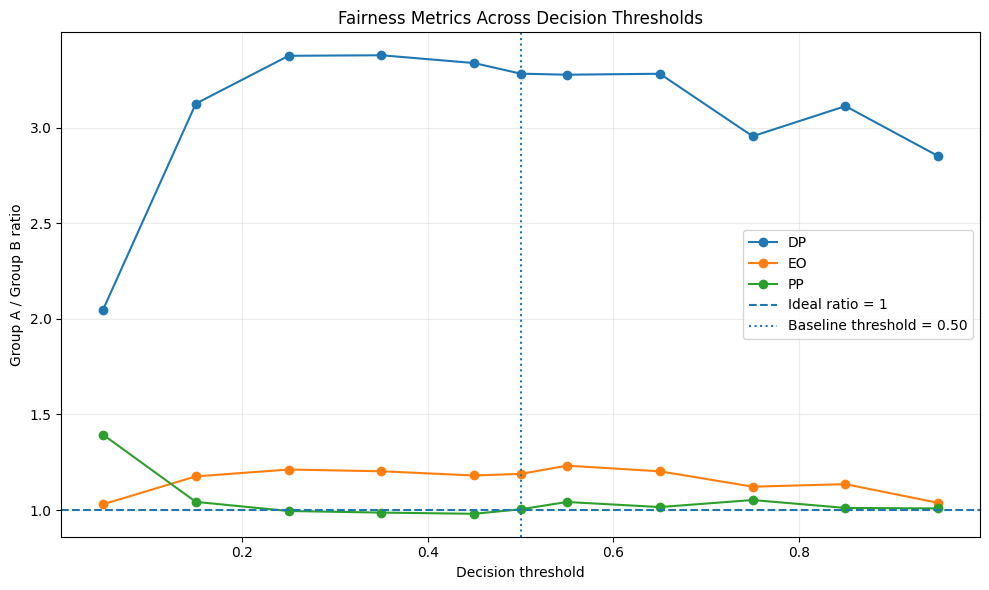

Cell 11 completed successfully.


In [ ]:
# CELL 11 — Baseline Classification and Fairness Analysis

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# --------------------------------------------------
# 1. Exact baseline threshold: 0.50
# --------------------------------------------------

baseline_threshold = 0.50

# Select fairness metrics at exactly 0.50.
baseline_fairness = fairness_results.loc[
    np.isclose(fairness_results["threshold"], baseline_threshold)
].copy()

if baseline_fairness.empty:
    raise ValueError(
        "Threshold 0.50 is missing from fairness_results. "
        "Rerun Cell 10 first."
    )

# Use probabilities directly to ensure the predictions
# correspond exactly to the 0.50 threshold.
baseline_predictions = (
    np.asarray(logistic_probabilities).reshape(-1)
    >= baseline_threshold
).astype(int)

y_test_array = np.asarray(y_test).reshape(-1).astype(int)

# Overall test-set classification metrics.
baseline = {
    "threshold": baseline_threshold,
    "accuracy": accuracy_score(
        y_test_array, baseline_predictions
    ),
    "precision": precision_score(
        y_test_array, baseline_predictions, zero_division=0
    ),
    "recall": recall_score(
        y_test_array, baseline_predictions, zero_division=0
    ),
    "f1": f1_score(
        y_test_array, baseline_predictions, zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_test_array, logistic_probabilities
    )
}

print("Baseline logistic regression metrics at threshold 0.50:")
display(pd.DataFrame([baseline]).round(4))


# --------------------------------------------------
# 2. Fairness metrics across all thresholds
# --------------------------------------------------

print("\nFairness results at every threshold:")

display(
    fairness_results[
        ["threshold", "DP", "EO", "PP", "accuracy"]
    ].round(4)
)

print("\nFairness metrics at the exact baseline threshold (0.50):")
display(
    baseline_fairness[
        ["threshold", "DP", "EO", "PP", "accuracy"]
    ].round(4)
)


# --------------------------------------------------
# 3. Plot fairness metrics across thresholds
# --------------------------------------------------

plt.figure(figsize=(10, 6))

for metric in ["DP", "EO", "PP"]:
    plt.plot(
        fairness_results["threshold"],
        fairness_results[metric],
        marker="o",
        label=metric
    )

plt.axhline(
    1.0,
    linestyle="--",
    linewidth=1.5,
    label="Ideal ratio = 1"
)

# Highlight the baseline threshold.
plt.axvline(
    baseline_threshold,
    linestyle=":",
    linewidth=1.5,
    label="Baseline threshold = 0.50"
)

plt.xlabel("Decision threshold")
plt.ylabel("Group A / Group B ratio")
plt.title("Fairness Metrics Across Decision Thresholds")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/part2_4_all_fairness_metrics.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# --------------------------------------------------
# 4. Save baseline results
# --------------------------------------------------

pd.DataFrame([baseline]).to_csv(
    f"{OUTPUT_DIR}/part2_4_baseline_classification.csv",
    index=False
)

baseline_fairness.to_csv(
    f"{OUTPUT_DIR}/part2_4_baseline_fairness_050.csv",
    index=False
)

print("Cell 11 completed successfully.")

In [ ]:
evidence = {
    "roll_number": ROLL_NUMBER,
    "random_state": RANDOM_STATE,
    "total_rows": len(X),
    "training_rows": len(X_train),
    "test_rows": len(X_test),
    "linear_prediction_median": float(linear_median),
    "linear_prediction_min": float(linear_predictions.min()),
    "linear_prediction_max": float(linear_predictions.max()),
    "threshold_mismatches": mismatch_count,
    "threshold_mismatch_percentage": float(mismatch_percentage),
    "high_confidence_errors": wrong_count,
    "high_confidence_error_percentage": float(wrong_percentage),
    "adversarial_subset_size": len(adversarial_sample),
    "largest_omitted_variable_shift": str(largest_shift),
    "largest_omitted_variable_absolute_change": float(
        ovb_results.loc[largest_shift, "absolute_change"]
    ),
    "logistic_accuracy_at_0_5": float(
        accuracy_score(y_test, logistic_predictions)
    ),
    "logistic_roc_auc": float(
        roc_auc_score(y_test, logistic_probabilities)
    )
}

evidence_df = pd.DataFrame(
    list(evidence.items()), columns=["metric", "value"]
)

display(evidence_df)
evidence_df.to_csv(
    f"{OUTPUT_DIR}/assignment_evidence_summary.csv", index=False
)

print("\nSaved evidence summary.")

,metric,value
0,roll_number,2139
1,random_state,139
2,total_rows,48790
3,training_rows,34153
4,test_rows,14637
5,linear_prediction_median,0.231046
6,linear_prediction_min,-0.381418
7,linear_prediction_max,1.681553
8,threshold_mismatches,4545
9,threshold_mismatch_percentage,31.051445



Saved evidence summary.


In [ ]:

# CELL 14 — Export model coefficients safely

import numpy as np
import pandas as pd
import json
import shutil
import os

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Flatten coefficient arrays to ensure one-dimensional columns.
linear_coef = np.asarray(model_a.coef_).reshape(-1)
logistic_coef = np.asarray(model_b.coef_).reshape(-1)
feature_list = np.asarray(feature_names).reshape(-1)

print("Number of features:", len(feature_list))
print("Linear coefficients:", len(linear_coef))
print("Logistic coefficients:", len(logistic_coef))

# Validate lengths before constructing the DataFrame.
if not (
    len(feature_list) == len(linear_coef) == len(logistic_coef)
):
    raise ValueError(
        "Feature and coefficient counts differ. "
        "Check the models and preprocessing output."
    )

coefficients_df = pd.DataFrame({
    "feature": feature_list,
    "linear_coefficient": linear_coef,
    "logistic_coefficient": logistic_coef
})

display(coefficients_df.head(20))

coefficients_df.to_csv(
    f"{OUTPUT_DIR}/model_coefficients.csv",
    index=False
)

# Export the evidence summary.
with open(f"{OUTPUT_DIR}/evidence_summary.json", "w") as f:
    json.dump(evidence, f, indent=2, default=str)

# Package all result files.
zip_path = shutil.make_archive(
    "CSET485_Assignment1_2139_results",
    "zip",
    OUTPUT_DIR
)

print("\nCoefficient table saved.")
print("Evidence summary saved.")
print("Results archive created:", zip_path)


Number of features: 96
Linear coefficients: 96
Logistic coefficients: 96


,feature,linear_coefficient,logistic_coefficient
0,numeric__age,0.030929,0.287421
1,numeric__fnlwgt,0.008939,0.078495
2,numeric__education-num,0.074998,0.733082
3,numeric__capital-gain,0.060072,2.341116
4,numeric__capital-loss,0.037732,0.270492
5,numeric__hours-per-week,0.038068,0.384255
6,categorical__workclass_Local-gov,-0.096021,-0.579739
7,categorical__workclass_Never-worked,-0.133785,-0.210812
8,categorical__workclass_Private,-0.083587,-0.528384
9,categorical__workclass_Self-emp-inc,-0.017462,-0.270388



Coefficient table saved.
Evidence summary saved.
Results archive created: /content/CSET485_Assignment1_2139_results.zip
